In [128]:
#https://kgptalkie.com/step-forward-step-backward-and-exhaustive-feature-selection-wrapper-method-kgp-talkie/
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, explained_variance_score, confusion_matrix, accuracy_score, classification_report, log_loss
from math import sqrt
from sklearn.feature_selection import SelectFromModel
#from sklearn.feature_selection import SelectKbest, SelectPercentile
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import roc_auc_score
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.preprocessing import StandardScaler

# to change scientific numbers to float
np.set_printoptions(formatter={'float_kind':'{:f}'.format})

#increase the size of sns plots
sns.set(rc={'figure.figsize':(12,10)})

In [129]:
#Loading  the  data
data = pd.read_csv('breast-cancer.csv', nrows = 300)

#print the shape
print(data.shape)

#runs the first 5 rows
data.head(5)

(300, 11)


,Id,Clump thickness,Uni_of_cell_size,Uni_of_cell_shape,Marginal adhesion,Single_epi_cell_size,Bare nuclei,Bland_Chromatin,Normal_nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [130]:
# Checking for null values
data.isnull()

,Id,Clump thickness,Uni_of_cell_size,Uni_of_cell_shape,Marginal adhesion,Single_epi_cell_size,Bare nuclei,Bland_Chromatin,Normal_nucleoli,Mitoses,Class
0,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
295,False,False,False,False,False,False,False,False,False,False,False
296,False,False,False,False,False,False,False,False,False,False,False
297,False,False,False,False,False,False,False,False,False,False,False
298,False,False,False,False,False,False,False,False,False,False,False


In [131]:
# Checking for null values
data.isnull().sum()

Id                       0
 Clump thickness         0
 Uni_of_cell_size        0
Uni_of_cell_shape        0
Marginal adhesion        0
 Single_epi_cell_size    0
Bare nuclei              0
 Bland_Chromatin         0
 Normal_nucleoli         0
 Mitoses                 0
 Class                   0
dtype: int64

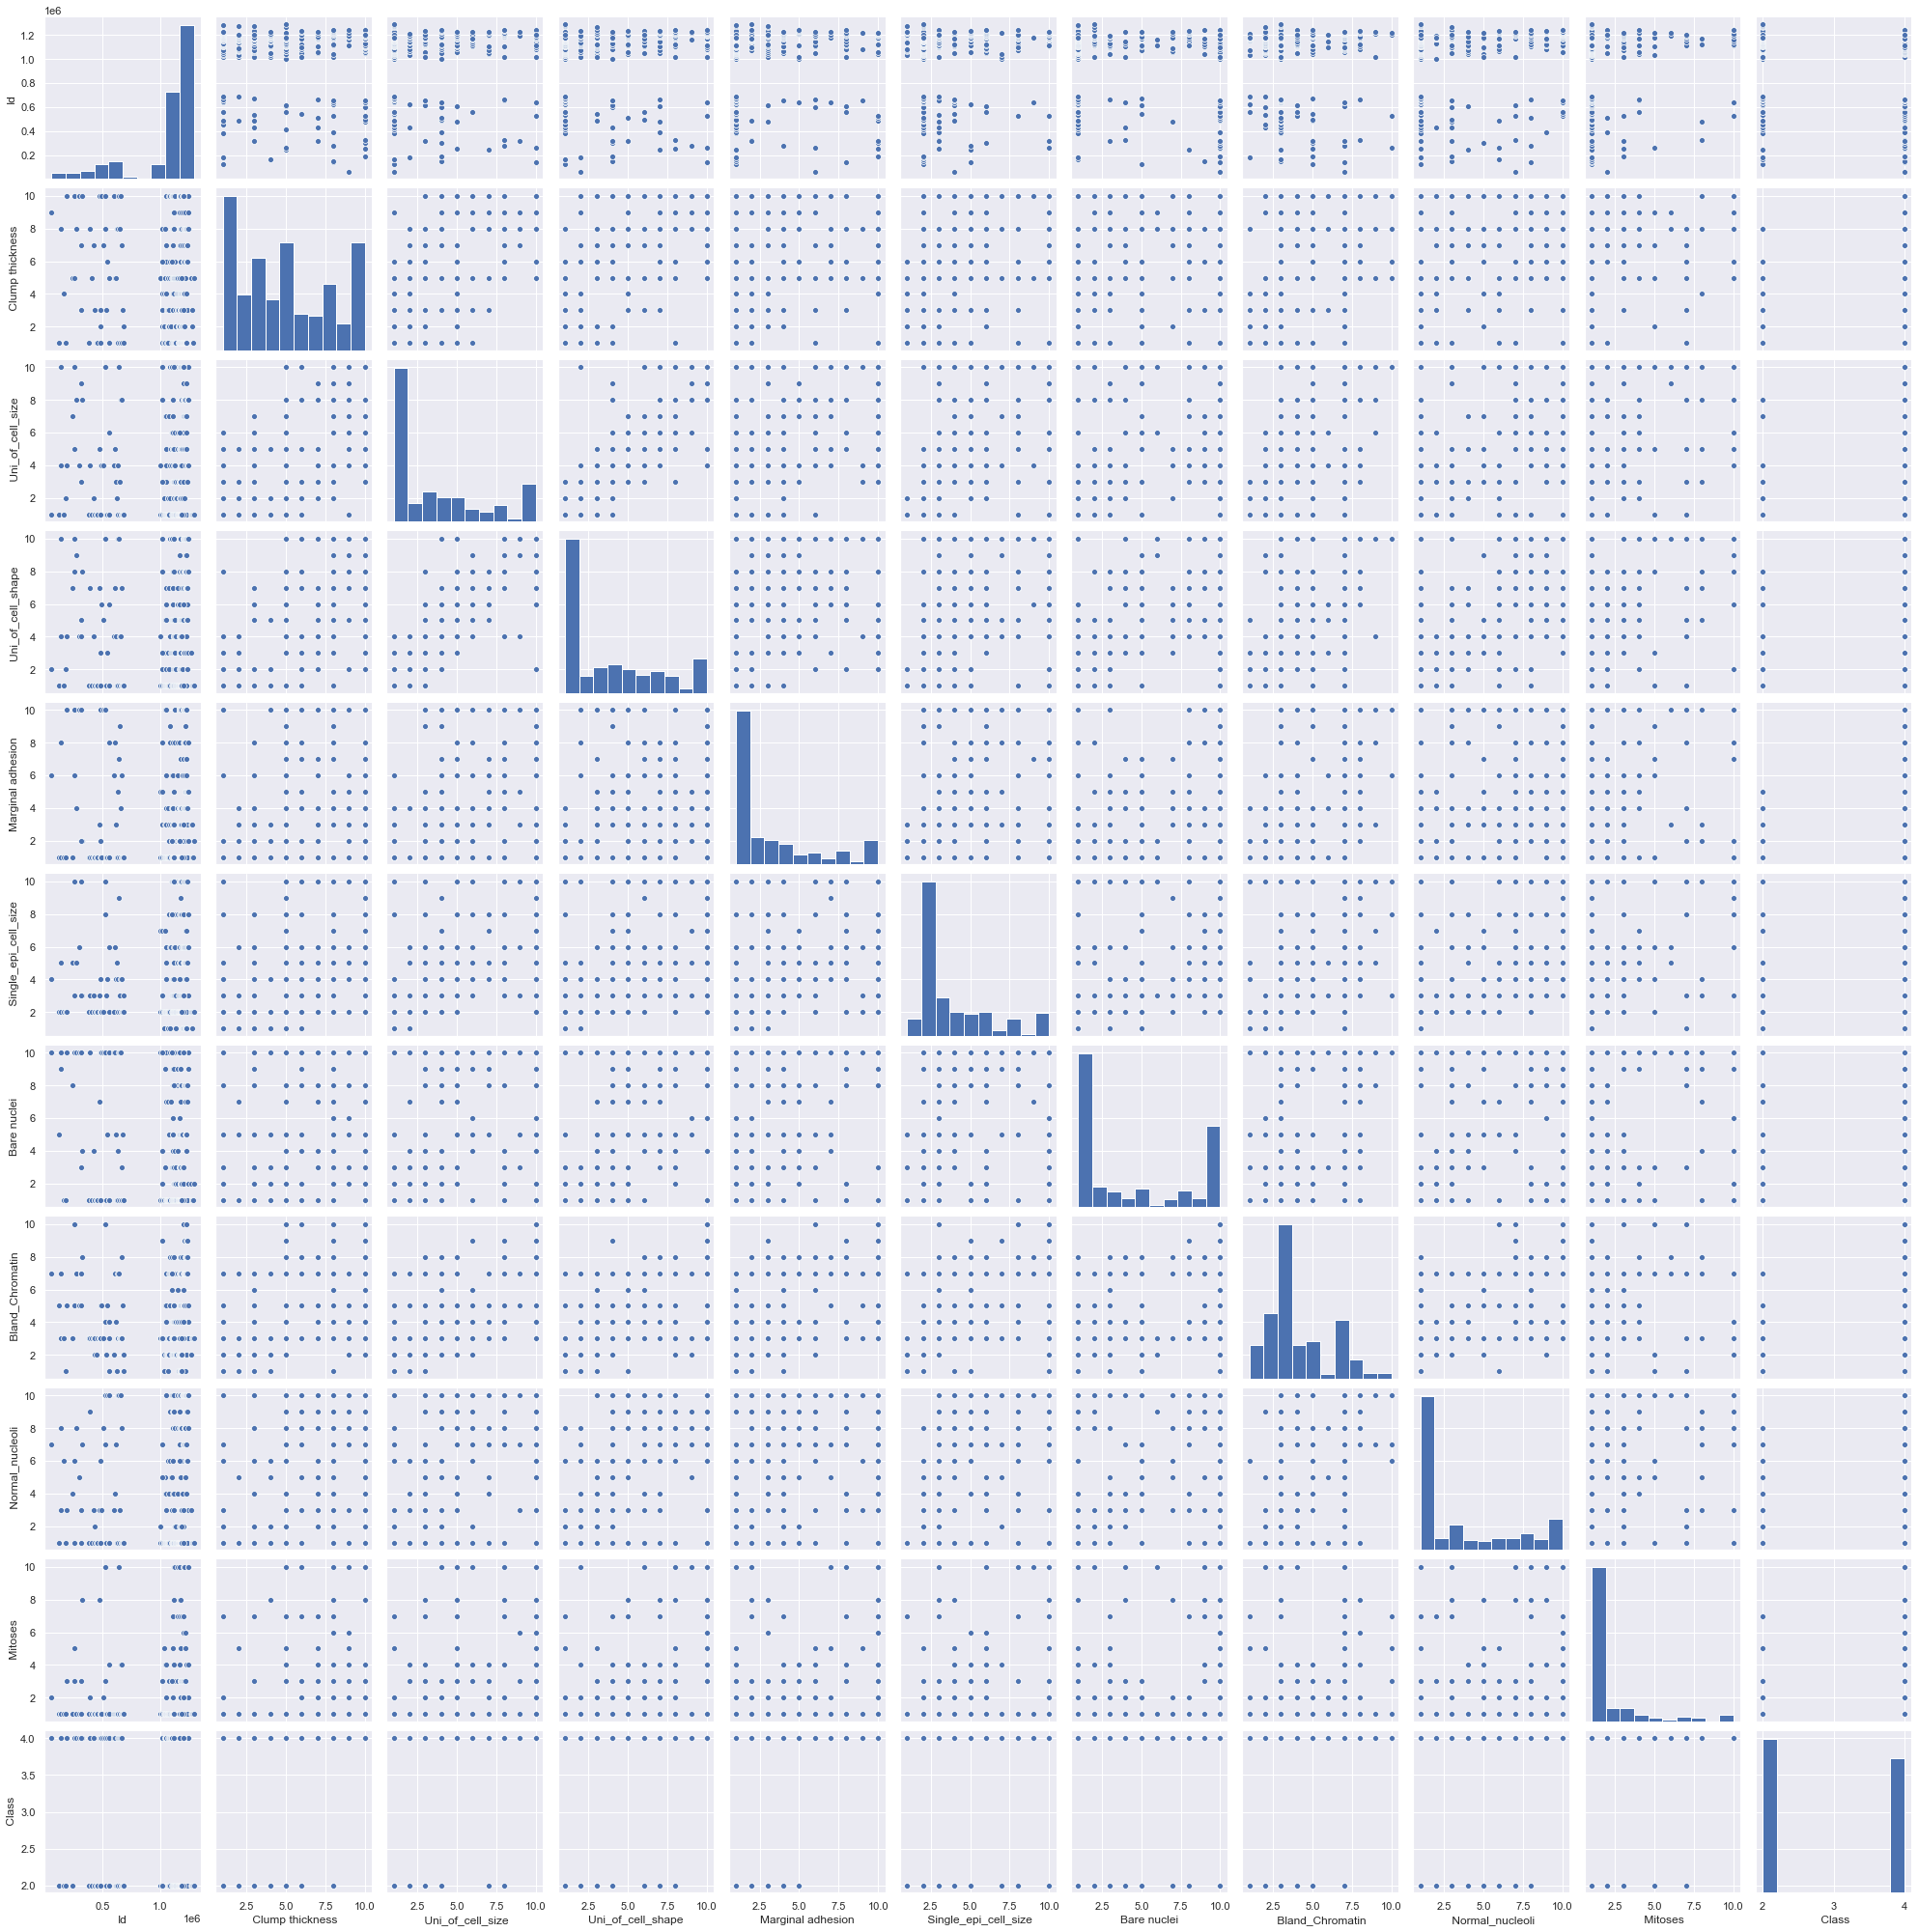

In [132]:
# Visualizing the data using seaborn pairplots
g = sns.pairplot(data)

In [133]:
data.shape

(300, 11)

In [134]:
# Split the data into x and y
x = data.iloc[:,1:9].values
y = data.iloc[:,10].values

#changing the values of last column
y[y==2] = 0
y[y==4] = 1

In [135]:
x.shape

(300, 8)

In [136]:
y

array([0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1,
       1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0,
       0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0], d

In [137]:
y.shape

(300,)

In [138]:
# Hold out validation

# Spliting the data into two parts : training and testing
x_train, x_test, y_train, y_valid = train_test_split(x, y, train_size = 0.6, test_size = 0.4, random_state = 2)

In [139]:
sfs = SFS(RandomForestClassifier(n_estimators=100, random_state=0, n_jobs = -1),
         k_features = 8,
          forward= True,
          floating = False,
          verbose= 2,
          scoring= 'accuracy',
          cv = 4,
          n_jobs= -1
         ).fit(x_train, y_train)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:    2.0s remaining:    3.4s
[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:    2.3s remaining:    0.0s
[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:    2.3s finished

[2021-01-04 19:15:00] Features: 1/8 -- score: 0.9277777777777778[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   4 out of   7 | elapsed:    2.1s remaining:    1.6s
[Parallel(n_jobs=-1)]: Done   7 out of   7 | elapsed:    2.1s finished

[2021-01-04 19:15:03] Features: 2/8 -- score: 0.9222222222222223[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   6 | elapsed:    2.0s remaining:    2.0s
[Parallel(n_jobs=-1)]: Done   6 out of   6 | elapsed:    2.0s finished

[2021-01-04 19:15:05] Features: 3/8 -- score: 0.9277777777777778[Parallel(n_jobs=-1)]: Using backend Lok

In [140]:
sfs.k_feature_idx_

(0, 1, 2, 3, 4, 5, 6, 7)

In [141]:
sfs.k_score_

0.9277777777777778

In [142]:
pd.DataFrame.from_dict(sfs.get_metric_dict()).T

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
1,"(1,)","[0.9555555555555556, 0.9333333333333333, 0.888...",0.927778,"(1,)",0.038818,0.0242161,0.0139812
2,"(1, 4)","[0.9111111111111111, 0.9333333333333333, 0.888...",0.922222,"(1, 4)",0.0398264,0.0248452,0.0143444
3,"(1, 3, 4)","[0.9333333333333333, 0.9555555555555556, 0.888...",0.927778,"(1, 3, 4)",0.038818,0.0242161,0.0139812
4,"(1, 2, 3, 4)","[0.9555555555555556, 0.9111111111111111, 0.888...",0.927778,"(1, 2, 3, 4)",0.0462741,0.0288675,0.0166667
5,"(1, 2, 3, 4, 5)","[0.9555555555555556, 0.9333333333333333, 0.888...",0.933333,"(1, 2, 3, 4, 5)",0.0436276,0.0272166,0.0157135
6,"(1, 2, 3, 4, 5, 6)","[0.9555555555555556, 0.9333333333333333, 0.888...",0.938889,"(1, 2, 3, 4, 5, 6)",0.0526854,0.0328671,0.0189758
7,"(0, 1, 2, 3, 4, 5, 6)","[0.9555555555555556, 0.9333333333333333, 0.866...",0.933333,"(0, 1, 2, 3, 4, 5, 6)",0.0666423,0.041574,0.0240027
8,"(0, 1, 2, 3, 4, 5, 6, 7)","[0.9555555555555556, 0.9333333333333333, 0.866...",0.927778,"(0, 1, 2, 3, 4, 5, 6, 7)",0.058397,0.0364302,0.021033


In [147]:
sfs.k_feature_names_

('7',)

In [144]:
#SEQUENTIAL BACKWARD SELECTION
sfs = SFS(RandomForestClassifier(n_estimators=100, random_state=0, n_jobs = -1),
         k_features = 1,
          forward= False,
          floating = False,
          verbose= 2,
          scoring= 'accuracy',
          cv = 4,
          n_jobs= -1
         ).fit(x_train, y_train)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:    2.1s remaining:    3.5s
[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:    2.6s remaining:    0.0s
[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:    2.6s finished

[2021-01-04 19:15:21] Features: 7/1 -- score: 0.9444444444444444[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   4 out of   7 | elapsed:    2.1s remaining:    1.6s
[Parallel(n_jobs=-1)]: Done   7 out of   7 | elapsed:    2.2s finished

[2021-01-04 19:15:23] Features: 6/1 -- score: 0.95[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   6 | elapsed:    2.1s remaining:    2.1s
[Parallel(n_jobs=-1)]: Done   6 out of   6 | elapsed:    2.1s finished

[2021-01-04 19:15:25] Features: 5/1 -- score: 0.9555555555555556[Parallel(n_jobs=-1)]: Using backend LokyBackend with 

In [145]:
pd.DataFrame.from_dict(sfs.get_metric_dict()).T

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
8,"(0, 1, 2, 3, 4, 5, 6, 7)","[0.9555555555555556, 0.9333333333333333, 0.866...",0.927778,"(0, 1, 2, 3, 4, 5, 6, 7)",0.058397,0.0364302,0.021033
7,"(0, 2, 3, 4, 5, 6, 7)","[0.9555555555555556, 0.9333333333333333, 0.911...",0.944444,"(0, 2, 3, 4, 5, 6, 7)",0.0398264,0.0248452,0.0143444
6,"(0, 2, 3, 4, 6, 7)","[0.9555555555555556, 0.9333333333333333, 0.933...",0.95,"(0, 2, 3, 4, 6, 7)",0.029536,0.0184257,0.0106381
5,"(0, 2, 4, 6, 7)","[0.9555555555555556, 0.9555555555555556, 0.933...",0.955556,"(0, 2, 4, 6, 7)",0.0251884,0.0157135,0.00907218
4,"(0, 4, 6, 7)","[0.9111111111111111, 0.9555555555555556, 0.955...",0.944444,"(0, 4, 6, 7)",0.0308494,0.019245,0.0111111
3,"(0, 4, 7)","[0.9111111111111111, 0.9333333333333333, 0.955...",0.938889,"(0, 4, 7)",0.029536,0.0184257,0.0106381
2,"(0, 7)","[0.9111111111111111, 0.9333333333333333, 0.933...",0.927778,"(0, 7)",0.0154247,0.0096225,0.00555556
1,"(7,)","[0.8444444444444444, 0.9333333333333333, 0.933...",0.894444,"(7,)",0.0635976,0.0396746,0.0229061


In [146]:
sfs.k_feature_idx_

(7,)